# COMP8410 Advanced Topic in Artificial Intelligence

# Notebook 1 - Trend Analysis (Which k-pop merchandise contributes is rising?)

### Introduction
This will work as an experiment of design products for next comeback of k-pop. To elarborate, it will conduct with various aspect such as:
 * Colours
 * Product types
 * Design
 Which three aspects will check if new product will gaining a popularity with K-pop fans

> This experiment will be a brief design of product in **Notebook 2- Design Generation**

| | System A - Standard System Overview | System B - Global System Overview|
|---|---|---|
| Model | **CLIP ViT-L/14** (Radford et al., ICML 2021) | **SigLIP 2 So400m** (Tschannen et al., 2025) |
| Training | contrastive softmax over 400M image–text pairs, English-centric | pairwise sigmoid loss + captioning + self-distillation, multilingual, de-biased data |

### Dataset
K-pop merchandise from **Amazon Reviews 2023** (McAuley Lab, UCSD; Hou et al., 2024), reviews up to Sep 2023. 
* Public Dataset which direct download and no token. 
* Images with a detected human face are removed, so no real artist's likeness is processed.
 
**References:**
Hou, Y., Li, J., He, Z., Yan, A., Chen, X., & McAuley, J. (2024). *Bridging Language and Items for Retrieval and Recommendation*. arXiv:2403.03952. [Amazon Reviews'23](https://amazon-reviews-2023.github.io)


### Linked with COMP8410 Knowledge
* Week 5 - CLIP measures text–image alignment
* W2 attention visualisation -> occlusion saliency maps 

# 1. Import Libraries and Set-up

In [ ]:
# Shared settings: identical in every notebook (if you change one, change all) 
from pathlib import Path
import os, sys, json, time, random, platform, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


# Experiment Settings for seed
SEED = 42


SYSTEMS = {"A": "Standard System Overview", "B": "Global System Overview"}

**GPU Checking**
* Cost estimation for computing unit and GPU type
* All of the price references and Google Colab Information in **ENV_SETUP.ipynb**

In [2]:
COLAB_PRICE_PER_UNIT_USD = 9.99 / 100

COLAB_UNITS_PER_HOUR_BY_GPU = {"T4": 1.19, "L4": 1.71, "A100": 5.40}


# GPU Detection
try:

    import torch

    _gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

except ImportError:

    _gpu = "CPU"


# Compute the approximate GPU cost per hour in USD
GPU_HOURLY_USD = next(
    (u for k, u in COLAB_UNITS_PER_HOUR_BY_GPU.items() if k in _gpu), 0.0 ) * COLAB_PRICE_PER_UNIT_USD

In [ ]:
#  Random Seed Function 
def set_seed(seed: int = SEED) -> None:

    
    random.seed(seed)

    np.random.seed(seed)

    try:
        import torch

        torch.manual_seed(seed)

        torch.cuda.manual_seed_all(seed)

    except ImportError:
        
        pass

In [ ]:
#  Device Detection Function 


def get_device() -> str:

    try:
        import torch

        if torch.cuda.is_available():

            return "cuda"

    except ImportError:
        pass

    return "cpu"



set_seed()


print(
    f"device: {get_device()} | "
    f"GPU: {_gpu} ≈ US${GPU_HOURLY_USD:.3f}/hour"
)

device: cuda | GPU: Tesla T4 ≈ US$0.119/hour


**Helper Function**

This will help me to check about run metadata (Dataset), timing, outcomes, which will use in all pairs model

So there is mainly feature:
* Check GPU 
* Model management
* Saved program environment
* GPU memory setuo
* Timimg measure
* Save final experiment result

In [ ]:
# GPU Type and Capability
def gpu_dtype():

    import torch

    if torch.cuda.is_available():

        if torch.cuda.get_device_capability()[0] >= 8:
            return torch.bfloat16
        else:
            return torch.float16

    return torch.float32

In [ ]:
# Transformers Output from AI model to Tensor Function - Model Management
def as_tensor(out):

    """get_*_features returns a tensor in transformers 4.x; newer versions may wrap it in an output object."""

    if hasattr(out, "pooler_output") and out.pooler_output is not None:

        return out.pooler_output

    if hasattr(out, "image_embeds"):
        
        return out.image_embeds

    if hasattr(out, "text_embeds"):

        return out.text_embeds

    return out if hasattr(out, "shape") else out[0]

In [ ]:
# Store Environment Information Function 

def env_info():

    """Saved inside every result file as evidence of when and where it was produced."""


    info = {

        "timestamp_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),

        "python": platform.python_version(),

        "os": platform.platform()

    }

    for pkg in ("torch", "transformers", "diffusers", "torch_geometric"):

        try:

            info[pkg] = __import__(pkg).__version__

        except Exception:

            info[pkg] = None

    try:

        import torch

        info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None


    except Exception:

        info["gpu"] = None

    return info

In [ ]:
# Logging Function for GPU Synchronization for Accurate Timing and Checking GPU working

def sync_gpu():

    try:

        import torch

        if torch.cuda.is_available():

            torch.cuda.synchronize()

    except ImportError:

        pass

In [9]:
# Free GPU Memory Function to Avoid Out of Memory Errors

def free_gpu():

    import gc

    gc.collect()

    try:

        import torch

        torch.cuda.empty_cache()

    except ImportError:

        pass

In [ ]:

# Timer -> for measuring latency and peak GPU memory usage, leading to performance evaluation and cost analysis of AI models

class Timer:
    #  check model performance from Latency and Peak VRAM


    def __init__(self):
        # Constructor will initialize the Timer object and set default values for latencies and peak VRAM usage.

        self.latencies, self.peak_vram_gb = [], None

        try:
           # start checking GPU
            import torch

            if torch.cuda.is_available():
    
                torch.cuda.reset_peak_memory_stats()

        except ImportError:

            pass




    def add(self, seconds, n_items=1):
        # this will calculate the average time per item and store it in the latencies list for further analysis.

        self.latencies.extend([seconds / n_items] * n_items)


    def finish(self):
        # this function is called after all processing is done to finalize the timing and memory usage data.
        try:

         # check GPU again
            import torch

            if torch.cuda.is_available():

                torch.cuda.synchronize()


                self.peak_vram_gb = torch.cuda.max_memory_allocated() / 1024**3
               # check GPU Memory usage and convert to GB

        except ImportError:

            pass

        return self



    def business(self):

        # this function summarizes the business performance metrics of the AI model to provide insights for business decision-making and cost analysis.

        mean = float(np.mean(self.latencies)) if self.latencies else float("nan")
        # Compute the average latency in seconds for processing each item, and handle cases where there are no latencies recorded by returning NaN.

        return {

            "mean_latency_s": round(mean, 4),


            "p95_latency_s": round(float(np.percentile(self.latencies, 95)), 4) if self.latencies else None,
             # 95th percentile latency, indicating that 95% of the items were processed in this time or less. If there are no latencies recorded, it returns None.

            "gpu_hourly_usd": round(GPU_HOURLY_USD, 4),

            "cost_per_1000_usd": round(mean * 1000 / 3600 * GPU_HOURLY_USD, 4),

            "peak_vram_gb": None if self.peak_vram_gb is None else round(self.peak_vram_gb, 2),
          
        }

In [ ]:
# JSON file handling function to manage data that cannot be directly converted to JSON, such as NumPy Scalars or special object types.
def _json_default(o):
    

    return o.item() if hasattr(o, "item") else str(o)

In [12]:
# Save Result Function

# Project folders: relative paths work on both Colab and Windows
ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
RAW = ROOT / "Datasets"
PROCESSED = RAW / "processed"
AMAZON_DIR = RAW / "Amazon2023_Merchandise_Data"
RESULTS = ROOT / "Results"
FIGURES, TABLES, METRICS = RESULTS / "figures", RESULTS / "tables", RESULTS / "metrics"
for _d in (PROCESSED, AMAZON_DIR, FIGURES, TABLES, METRICS):
    _d.mkdir(parents=True, exist_ok=True)


def save_result(task, system, model_id, technical, business,
                governance, notes="", items=None, extra=None):

    records = {

        "task": task,

        "system": system,

        "model_id": model_id,

        "technical": technical,

        "business": business,

        "governance": governance,

        "notes": notes,

        "env": env_info(),

        "extra": extra or {}

    }

    path = METRICS / f"{task}__{system}.json"

    path.write_text(
        json.dumps(
            records,
            indent=2,
            ensure_ascii=False,
            default=_json_default
        ),
        encoding="utf-8"
    )

    if items is not None:

        items.to_csv(
            TABLES / f"{task}__{system}_items.csv",
            index=False
        )

    print("saved", path)

    return records

# 2. Task settings

All settings for this notebook in one place.
`QUICK = True` runs a small sample for testing; set it to `False` for the final results.

**System A uses CLIP and System B uses SigLIP 2; both tag product images by colour and product type.**

> For your information, Thai is my mother language and Korean is my third language so it will be a main reason for me to work with Korean language in this task and choose K-pop industry per my interesting as well

In [ ]:

TASK = "1_Trend_Analysis"

# QUICK TEST SETTINGS
QUICK = True


# MODEL CONFIGURATION

MODELS = {
    "A": {
        "id": "openai/clip-vit-large-patch14",
        "kind": "clip"
    },
    "B": {
        "id": "google/siglip2-so400m-patch14-384",
        "kind": "siglip"
    }
}


# SYSTEM SELECTION
RUN_SYSTEMS = ["A", "B"]
for system in RUN_SYSTEMS:
    assert system in SYSTEMS, f"{system} is not defined in SYSTEMS"
    assert system in MODELS, f"{system} is not defined in MODELS"

# Show selected system names
for system in RUN_SYSTEMS:
    print(f"System {system}: {SYSTEMS[system]}")
    print(f"Model: {MODELS[system]['id']}")



# DATA SOURCE CONFIGURATION
BASE_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/"

# Amazon categories to search for K-pop merchandise (filtered by KEYWORDS).
# Amazon_Fashion adds apparel people that might not usual with Kpop.
CATEGORIES = ["CDs_and_Vinyl", "Amazon_Fashion"]


# KEYWORD CONFIGURATION in K-pop based
KEYWORDS = [
    "kpop",
    "k-pop",
    "lightstick",
    "light stick",
    "photocard holder",
    "official merch",
    "fan merch"
]


# DATA LIMIT CONFIGURATION
# QUICK = True used maximum at 800 records
# QUICK = False used maximum at 3000 records
MAX_ITEMS = 800 if QUICK else 3000



# TREND ANALYSIS PARAMETERS
'''
WINDOW_MONTHS = check the last 6 months of data for trend analysis
HORIZON_MONTHS = forecast the next 3 months based on the trend analysis
TOP_K = select the top 3 results based on trend analysis
N_CUTOFFS = use 6 cutoffs for evaluation
'''
WINDOW_MONTHS, HORIZON_MONTHS, TOP_K, N_CUTOFFS = 6, 3, 3, 6




# FACE FILTERING CONFIGURATION
'''
This will avoid the model use people face due to rights and privacy must be considered
Which True = will enable face filtering to remove or ignore images containing human faces,
False = will not enable face filtering which I will check and fix code to avoid using human face for project
'''
DROP_FACES = True


# PRODUCT ATTRIBUTE CONFIGURATION - Design 
ATTRIBUTES = {

    "colour": [
        "black",
        "white",
        "pink",
        "purple",
        "blue",
        "pastel",
        "red",
        "green",
        "yellow",
        "grey"
    ],


    "product": [
        "t-shirt",
        "hoodie",
        "bag",
        "lightstick",
        "sticker",
        "keyring",
        "phone case",
        "photocard holder",
        "poster",
        "tea cup",
        "card",
        "album"
    ],
}



# PROMPT CONFIGURATION -> will be used to generate prompts for AI models to analyze product images and attributes.
PROMPT_TEMPLATES = [
    "a product photo of a {} item",
    "{}"
]


# MULTILINGUAL FAIRNESS CONFIGURATION -> includes Korean and Thai Language

COLOUR_LABELS = {

    "Korean": [
        "검은색",  # Black
        "흰색",    # White
        "분홍색",  # Pink
        "보라색",  # Purple
        "파란색",  # Blue
        "파스텔",  # Pastel
        "빨간색",  # Red
        "초록색",  # Green
        "노란색",  # Yellow
        "회색"     # Gray
    ],

  
    "Thai": [
        "สีดำ",       # Black
        "สีขาว",      # White
        "สีชมพู",     # Pink
        "สีม่วง",      # Purple
        "สีฟ้า",       # Blue
        "สีพาสเทล",   # Pastel
        "สีแดง",      # Red
        "สีเขียว",     # Green
        "สีเหลือง",   # Yellow
        "สีเทา"    # Gray
    ],
}


System A: Standard System Overview
Model: openai/clip-vit-large-patch14
System B: Global System Overview
Model: google/siglip2-so400m-patch14-384


# 3. Data Loading Function

* The category files are large, so they are downloaded once to Dataset Folder and **streamed line by line**; only K-pop items are kept in memory. 
* Reference labels come from the product title (e.g. "pink lightstick case" : colour = pink, product = lightstick); a title with no or several matching words gets no label.

In [14]:
# import libraries for data processing and analysis
import gzip, io                 # for reading compressed .gz files and handling image data in memory
import requests                 # for downloading data from websites
from tqdm.auto import tqdm      # for displaying progress bars during processing


# STREAM JSONL.GZ -> check if data file exist in here

def stream_jsonl_gz(url, cache):
    if not cache.exists():

        cache.parent.mkdir(parents=True, exist_ok=True)

        tmp = cache.with_suffix(".part") # temporary file for downloading

        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            # Download data and check for HTTP errors
            with open(tmp, "wb") as fh:
                # open temporary file for writing binary data

                for chunk in r.iter_content(1 << 20):
                    # Download data in 1 MB chunks to reduce RAM usage
                    fh.write(chunk)

        tmp.replace(cache)
        # Replace temporary file with cache file when download is complete

    with gzip.open(cache, "rt", encoding="utf-8") as fh:
        # Open .gz file in UTF-8 text mode

        for line in fh:
            # Read data line by line

            yield json.loads(line)
            # transform each line of JSON text into a Python dictionary and yield it one at a time for processing

In [ ]:

# LOAD K-POP ITEMS - related to trend analysis and product information extraction from Amazon data
def load_kpop_items():

    rows, kws = [], [k.lower() for k in KEYWORDS]
    # rows for storing product data, kws for storing keywords in lowercase for case-insensitive matching
    # kws for storing keywords in lowercase for case-insensitive matching

    quota = MAX_ITEMS // len(CATEGORIES)
    # divide the maximum number of items evenly across the categories - each must be similar maximum

    for cat in CATEGORIES:
        # check each category for K-pop merchandise

        start = len(rows)
        # Record the number of items before starting to read this category

        for rec in tqdm(
            stream_jsonl_gz(
                f"{BASE_URL}meta_categories/meta_{cat}.jsonl.gz",
                AMAZON_DIR / f"meta_{cat}.jsonl.gz"
            ),
            desc=f"meta {cat}"
        ):
            # Load or read product details and show a progress bar while reading data

            title = (rec.get("title") or "").lower()
            # pull the product title and convert it to lowercase for case-insensitive matching

            if any(k in title for k in kws):
                # check if the product title contains any of the keywords defined in kws

                imgs = rec.get("images") or []
                # image pull out

                main = next(
                    (i for i in imgs if i.get("variant") == "MAIN"),
                    imgs[0] if imgs else {}
                )


                rows.append({
                    "parent_asin": rec.get("parent_asin"),
                    "title": rec.get("title"),
                    "category": cat,
                    "price": rec.get("price"),
                    "image_url": main.get("large") or main.get("hi_res")
                })
                # record the product information including parent ASIN, title, category, price, and image URL

            if len(rows) - start >= quota:
                # check if this category has enough items according to the allocated quota
                break
                # stop reading this category when the quota is met

    return (
        pd.DataFrame(rows)
        .dropna(subset=["parent_asin", "image_url"])
        .drop_duplicates("parent_asin")
        .reset_index(drop=True)
    )
    # Translation: Convert the data into a DataFrame, remove entries without product IDs or image URLs, remove duplicate parent_asin entries, and reset the index.


In [ ]:

# LOAD REVIEWS
def load_reviews(asins):

    rows = []
    # List for review records from Amazaon

    for cat in CATEGORIES:

        for rec in tqdm(
            stream_jsonl_gz(
                f"{BASE_URL}review_categories/{cat}.jsonl.gz",
                AMAZON_DIR / f"review_{cat}.jsonl.gz"
            ),
            desc=f"reviews {cat}"
        ):
            # read review from amazon

            if rec.get("parent_asin") in asins:
                # choose only our target

                rows.append({
                    "parent_asin": rec["parent_asin"],
                    "timestamp": rec.get("timestamp"),
                    "rating": rec.get("rating")
                })
                #  record product ID, user review detials with time

    rv = pd.DataFrame(rows)
    # Transform into DataFrame

    assert not rv.empty, "no reviews found for the selected items"
    # Final check if review exist

    rv["month"] = pd.to_datetime(
        rv["timestamp"], unit="ms"
    ).dt.to_period("M")
    # change timestamp to be montly record

    return rv

In [ ]:

# DOWNLOAD IMAGES
def download_images(items, out_dir=AMAZON_DIR / "images"):

    '''if record image or filter image incomplte
    and filter people face founded -> DROP_FACES = TRUE'''

    from PIL import Image

    out_dir.mkdir(parents=True, exist_ok=True)

    det = None
    # Face Detector
    if DROP_FACES:

        import cv2

        det = cv2.CascadeClassifier(
            cv2.data.haarcascades +
            "haarcascade_frontalface_default.xml"
        )
        # for detect human face

    keep, n_face = [], 0
    # keep - record image data for monitorinh
    # n_face - count faces img

    for _, r in tqdm(
        items.iterrows(),
        total=len(items),
        desc="images"
    ):

        path = out_dir / f"{r['parent_asin']}.jpg"

        try:

            if not path.exists():

                resp = requests.get(r["image_url"], timeout=20)

                resp.raise_for_status()

                Image.open(
                    io.BytesIO(resp.content)
                ).convert("RGB").save(path, quality=90)


            if det is not None:

                gray = cv2.cvtColor(
                    cv2.imread(str(path)),
                    cv2.COLOR_BGR2GRAY
                )

                if len(det.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))):

                    n_face += 1

                    path.unlink(missing_ok=True)

                    continue

            keep.append({
                **r.to_dict(),
                "image_path": str(path)
            })
            # record img wiht located

        except Exception:
            # if error

            continue

    print(
        f"kept {len(keep)} images, removed {n_face} with a detected faces"
    )
    # 

    return pd.DataFrame(keep)
    # return as DataFrame


In [ ]:
# TITLE LABEL

def title_label(title, values):

    ''' if found just one word of products, set as label
    if not and found so many , set as None'''

    t = f" {str(title).lower()} "

    hits = [
        v for v in values
        if any(f" {v}{end}" in t for end in (" ", ",", "s ", "-"))
    ]
    # check symbolic too

    return hits[0] if len(hits) == 1 else None

# 4. Trend logic


For each cut-off month (**T**), three different rankings are compared:

* **Model forecast:** The model's predicted tags are ranked based on how much their review counts have grown. This is calculated by comparing the latest 3 months with the previous 3 months. A smoothing value of +1 is added to avoid division by zero.
* **Naive forecast:** Tags are ranked by their total number of reviews over the past 6 months. This provides a simple baseline based on the idea that products that performed well recently may continue to attract attention.
* **Ground truth:** Tags identified from product titles are ranked based on their review growth over the following 3 months (**T+1** to **T+3**).

To keep the evaluation fair, forecasts only use data available up to month **T**. This prevents future information from influencing the predictions.

**Trend precision@k** measures how many of the forecast's top 3 tags also appear in the ground truth's top 3. The scores are calculated across 6 different cut-off points and then averaged using a rolling-origin backtest.

The main goal is to see whether the models can perform better than the naive forecast. If a model cannot outperform this simple baseline, its ability to identify emerging trends may be limited.

---

### Rationale for the Study in Trend Logic Section 
 
> **This will describe why 3 - 6 months in Logic measurement**

My interest in the global entertainment industry, including music, films, artists, and their related merchandise markets, has led me to explore how consumer interests and product trends change over time. From my personal experience as someone who follows the entertainment industry, I have noticed that audience interests and merchandise demand can shift quite quickly. A particular artist, release, or product may attract significant attention one month, while interest may move towards something else in the following months.

This is particularly interesting in an industry where new releases, events, collaborations, and fan activities can influence consumer behaviour. K-pop is one example of this, but similar changes can also be observed across other areas of the global entertainment industry.

Industry reports also highlight changes in entertainment consumption and merchandise purchasing behaviour. For example, reports from the Korea Creative Content Agency (2025) and Weverse Company (2025) show changes in K-pop consumption and merchandise sales, while Hanteo News (2025) highlights differences in album sales trends across artists.

These observations provide a reason to look beyond total review counts and examine how product interest changes over time. Therefore, this notebook uses rolling monthly periods to identify products that may be gaining attention and to evaluate whether System A and System B can recognise emerging trends more effectively than a simple baseline.


**References**
- Hanteo News. (2025, January 16). *2024 K-pop trend report*. https://www.hanteonews.com/en/article/74681
- Korea Creative Content Agency. (2025). *2025 global trends in K-pop consumption*. https://welcon.kocca.kr/cmm/fms/FileDown.do?atchFileId=FILE_ba6300f2-5443-42ed-b5ab-339adeeaec96&fileSn=1&preview=Y
- Shin, S., & Park, J. (2018). On-chart success dynamics of popular songs. *Advances in Complex Systems, 21*(03n04), 1850008. https://doi.org/10.1142/S021952591850008X
- Weverse Company. (2025, January 23). *Weverse issues global fandom trend report, offering new insights on superfan business*. https://en.weverse.co/news/?bmode=view&idx=165565023
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/

In [ ]:
def precision_k(predicted, actual, k=TOP_K):
    # Calculate the percentage of Top_k tags that direct with real values
    return len(set(list(predicted)[:k]) & set(list(actual)[:k])) / k


def monthly_counts(reviews, tags, attr):
    # Combine information of review + products tag and match with parent_asin
    merged = reviews.merge(tags[["parent_asin", attr]].dropna(), on="parent_asin")

    # Count each month review + tags
    return merged.groupby(["month", attr]).size().unstack(fill_value=0).sort_index()

def duration(counts, start_excl, end_incl):
    # chose start and end
    return counts.loc[(counts.index > start_excl) & (counts.index <= end_incl)]


def rank_growth(counts, end, window=WINDOW_MONTHS):
    # pull past data follow my set up
    hist = duration(counts, end - window, end)
    half = max(1, window // 2)

    return ((hist.iloc[-half:].sum() + 1) / (hist.iloc[:-half].sum() + 1)).sort_values(ascending=False).index.tolist()


def ranking_tag(counts, end, window=WINDOW_MONTHS):
    # ranking tag during duration
    return duration(counts, end - window, end).sum().sort_values(ascending=False).index.tolist()


def actual_growth(counts, end, horizon=HORIZON_MONTHS):
    # Compare a number of future review with previous review
    future, past = duration(counts, end, end + horizon).sum(), duration(counts, end - horizon, end).sum()

    # Measure and ranking future review prediction
    return ((future + 1) / (past + 1)).sort_values(ascending=False).index.tolist()


def trend_backtest_info_check(pred_counts, ref_counts):
    months = ref_counts.index
    if len(months) < WINDOW_MONTHS + HORIZON_MONTHS + 1:
        return {"trend_precision_k": float("nan"), "naive_precision_k": float("nan"), "cutoffs": []}

    # Choose cutsoff of data -> prevent over data loader
    cutoffs = list(months[WINDOW_MONTHS: len(months) - HORIZON_MONTHS])[-N_CUTOFFS:]
    model_p, naive_p = [], []

    for end in cutoffs:
        # Use actual growth for grounding truth to compare
        truth = actual_growth(ref_counts, end)

        # measure model prediction
        model_p.append(precision_k(rank_growth(pred_counts, end), truth))
        naive_p.append(precision_k(ranking_tag(ref_counts, end), truth))

    return {"trend_precision_k": float(np.mean(model_p)), "naive_precision_k": float(np.mean(naive_p)),
            "cutoffs": [str(c) for c in cutoffs]}

**Unit Test for Logic - Trend Analysis**

In [20]:
# Assumption scenario for Testing only 

months = pd.period_range("2022-01", periods=18, freq="M")


# Trend check up about coulor objects interesting
toy = pd.DataFrame({
    "pink": np.linspace(1, 40, 18),
    "black": np.linspace(60, 30, 18),
    "blue": np.full(18, 20.0)
}, index=months)


k = TOP_K
TOP_K = 1


res = trend_backtest_info_check(toy, toy)

# check if find pink
assert rank_growth(toy, months[10], WINDOW_MONTHS)[0] == "pink"

# Precision Checking
assert precision_k(["pink"], ["pink"], 1) == 1.0
assert precision_k(["black"], ["pink"], 1) == 0.0

# cutoff checking
end = months[10]
assert duration(toy, end - WINDOW_MONTHS, end).index.max() == end, "Past data must stop at the cut-off point"

# Check ground truth after cutoof
assert duration(toy, end, end + HORIZON_MONTHS).index.min() > end, "truth duration must start after the cut-off point"

TOP_K = k

# Check Label
assert title_label("Pink Lightstick Case", ATTRIBUTES["colour"]) == "pink"

# multi colors will not flag
assert title_label("Black and white poster", ATTRIBUTES["colour"]) is None

# FInal check
print("PASS -> backtest use only past data -> toy trend detected")

PASS -> backtest use only past data -> toy trend detected


# 5. Dataset Loading
* It will load k-pop items, images, and reviews

In [21]:
# pull kpop item from dataset
Kpop_items = load_kpop_items()

# download and filter imgaes + products which will check as well if pass my condition or not
Kpop_items = download_images(Kpop_items)

# Ref label set up
for attr, values in ATTRIBUTES.items():
    Kpop_items[f"ref_{attr}"] = Kpop_items["title"].map(
        lambda t: title_label(t, values)
    )

# Load only locked dataset in needs
reviews = load_reviews(set(Kpop_items["parent_asin"]))

# saved and cleaned it in csv
Kpop_items.to_csv(PROCESSED / "amazon_kpop_items.csv", index=False)

# shown a number of products, review, & review duration
print(
    len(Kpop_items), "Items |",
    len(reviews), "Reviews |",
    reviews["month"].min(), "to", reviews["month"].max()
)

# check rational of product yhat can identify ref label in each cat
print(
    "Title Label Coverage:",
    {a: round(Kpop_items[f"ref_{a}"].notna().mean(), 3) for a in ATTRIBUTES}
)

# Sample Display
Kpop_items[["title", "ref_colour", "ref_product"]].head(8)

meta CDs_and_Vinyl: 0it [00:00, ?it/s]

meta Amazon_Fashion: 0it [00:00, ?it/s]

images:   0%|          | 0/686 [00:00<?, ?it/s]

kept 567 images, removed 119 with a detected faces


reviews CDs_and_Vinyl: 0it [00:00, ?it/s]

reviews Amazon_Fashion: 0it [00:00, ?it/s]

567 Items | 1864 Reviews | 2013-11 to 2023-08
Title Label Coverage: {'colour': np.float64(0.176), 'product': np.float64(0.561)}


,title,ref_colour,ref_product
0,Angel's Last Mission : Love OST 2019 Korean KB...,None,None
1,BTS 3rd Album [In The Mood For Love ] PT.1 CD ...,None,album
2,Descendants Of The Sun VOL.1 OST 2016 Korean D...,None,None
3,Fromis_9 - [Fun Factory] 1st Single Album Rand...,None,album
4,Stray Kids - [Cle 1:Miroh] Normal Album Random...,None,album
5,Stray Kids Noeasy 2nd Album Limited Version CD...,None,None
6,"BTS 2nd Mini Album [SKOOL LUV AFFAIR] CD,115p ...",None,album
7,Oneus 'In Its Time' 1st Single Album CD+1p Sto...,None,None


**Data Validation** -> check if dataset ready

In [ ]:
# Check if product have 100 record at least -> if less than , it will ask to add more
assert len(Kpop_items) >= 100, f"only {len(Kpop_items)} Kpop_items: add a category or keywords"

# Check if there is 50 record at least for label' product (one kind each) such as ref colour, ref product
assert Kpop_items[["ref_colour", "ref_product"]].notna().any(axis=1).sum() >= 50, "too few title labels"

# check if the number of month review enough for back test -> it need to have at least past info 
assert reviews["month"].nunique() >= WINDOW_MONTHS + HORIZON_MONTHS + 1, "not enough months for the backtest"

# Check if all reviews of products is in Kpop_items -> protect review will not include in products in dataste
assert set(reviews["parent_asin"]) <= set(Kpop_items["parent_asin"]), "reviews for items that were dropped"

# Show Result -> if pass all condition
print("PASSED", reviews["month"].nunique(), "Months of review")

PASSED 112 Months of review


# 6. Zero-shot tagging and evaluation

Both models use a **zero-shot approach** to classify product images.
* This means each image is compared with a set of text labels, such as **a product photo of a pink item**, and the model selects the label that best matches the image. 
* Since the models do not need additional training, new colour or product labels can be added without retraining them.

### The evaluation focuses on three main areas:

**1. Technical performance** 
* I will compare each model's colour and product predictions with the reference labels identified from product titles, using **macro-F1**. 
This metric gives equal importance to each class, meaning less common colours are considered just as important as more common ones. 
* Then I will also use **trend precision@k** to compare the models with a simple naive forecast. 
* This helps me to see whether the models can identify emerging trends more effectively than relying on products that performed well in the previous period.
* **Governance:** I test colour classification using English, Korean and Thai labels on the same set of images -> It will treat like fairness. 
* The difference between the highest and lowest F1 scores is used to measure the **multilingual performance gap**. 

> Consequently, the results across languages helps reveal differences that might be hidden by an overall average. This is particularly relevant to entertainment industry as its fans come from different language backgrounds. Then I will use language based on knowledge for make sure the correctness of language tyoo.


**2. Business performance** 
* I measure the average time needed to process one image and estimate the cost of processing 1,000 images. 
* As a result, I can use it to consider cost alongside accuracy helps determine whether any improvement in performance is worth the additional computing resources.


**References**
- Barocas, S., Hardt, M., & Narayanan, A. (2023). *Fairness and machine learning: Limitations and opportunities*. MIT Press. https://fairmlbook.org
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/
- Luccioni, S., Jernite, Y., & Strubell, E. (2024). Power hungry processing: Watts driving the cost of AI deployment? *Proceedings of the 2024 ACM Conference on Fairness, Accountability, and Transparency (FAccT '24)*. https://arxiv.org/abs/2311.16863
- Opitz, J. (2024). A closer look at classification evaluation metrics and a critical reflection of common evaluation practice. *Transactions of the Association for Computational Linguistics, 12*, 820–836. https://aclanthology.org/2024.tacl-1.46
- Radford, A., Kim, J. W., Hallacy, C., Ramesh, A., Goh, G., Agarwal, S., Sastry, G., Askell, A., Mishkin, P., Clark, J., Krueger, G., & Sutskever, I. (2021). Learning transferable visual models from natural language supervision. *Proceedings of the 38th International Conference on Machine Learning*, 8748–8763.
- Tschannen, M., Gritsenko, A., Wang, X., Naeem, M. F., Alabdulmohsin, I., Parthasarathy, N., Evans, T., Beyer, L., Xia, Y., Mustafa, B., Hénaff, O., Harmsen, J., Steiner, A., & Zhai, X. (2025). *SigLIP 2: Multilingual vision-language encoders with improved semantic understanding, localization, and dense features*. arXiv:2502.14786. https://arxiv.org/abs/2502.14786

In [23]:
!pip install scikit-learn
!pip install -y transformer


Usage:   
  pip3 install [options] <requirement specifier> [package-index-options] ...
  pip3 install [options] -r <requirements file> [package-index-options] ...
  pip3 install [options] [-e] <vcs project url> ...
  pip3 install [options] [-e] <local project path> ...
  pip3 install [options] <archive url/path> ...

no such option: -y


In [24]:
import torch
from PIL import Image
from sklearn.metrics import f1_score



# ZERO-SHOT IMAGE CLASSIFICATION ->  create class for model predicts image' label 
class ZeroShottag:

    def __init__(self, model_id, kind):

        # Load model and Processor from Hugging Face
        from transformers import AutoModel, AutoProcessor

        # GPU identifier - computing
        self.kind, self.dev = kind, get_device()

        # Data type for GPU
        self.dtype = gpu_dtype() if self.dev == "cuda" else torch.float32

        # Load Model ID follow above define
        self.model = AutoModel.from_pretrained(
            model_id, dtype=self.dtype
        ).to(self.dev).eval()

        # โหลด Processor สำหรับเตรียมข้อความและรูปภาพก่อนเข้าโมเดล
        # Laod Processor for data preparation such as text & images before model processing
        self.proc = AutoProcessor.from_pretrained(model_id)


    # Text to Text Embeddings
    def encode_text(self, labels, templates):

        # Padding pattern define for specialize model -> SigLIP = length 64 tokens, CLIP using Padding follow text lenght
        pad = {"padding": "max_length", "max_length": 64} if self.kind == "siglip" else {"padding": True}

        embs = []

        for tpl in templates:

            # Label put into Prompt Template such as "a photo of {}" to "a photo of red"
            inp = self.proc(
                text=[tpl.format(l) for l in labels],
                return_tensors="pt",
                truncation=True,
                **pad
            ).to(self.dev)

            with torch.no_grad():

                # text = text embedding -> nomalize for text lenght : vector =  1
                embs.append(
                    torch.nn.functional.normalize(
                        as_tensor(self.model.get_text_features(**inp)).float(),
                        dim=-1
                    )
                )

        return torch.nn.functional.normalize(
            torch.stack(embs).mean(0), dim=-1
        )


    # Image to Image Embeddings
    def encode_images(self, images):

        # prepare img
        inp = self.proc(images=images, return_tensors="pt").to(self.dev)

        inp["pixel_values"] = inp["pixel_values"].to(self.dtype)

        with torch.no_grad():

            return torch.nn.functional.normalize(
                as_tensor(self.model.get_image_features(**inp)).float(),
                dim=-1
            )

    # Predict label from img

    def classify(self, paths, vocab, templates, batch=32, timer=None):

        # Transform Label for each of attribute in text embeddings  such as colour and products
        text = {
            a: self.encode_text(v, templates)
            for a, v in vocab.items()
        }

        rows = []

        # Divide picture as batch for control memeory unit
        for i in range(0, len(paths), batch):

            chunk = paths[i:i + batch]

            imgs = [Image.open(p).convert("RGB") for p in chunk]

            t0 = time.perf_counter()

            emb = self.encode_images(imgs)

            # Calculate similarity between image embeddings
            preds = {
                a: (emb @ te.T).argmax(1).cpu().numpy()
                for a, te in text.items()
            }

            sync_gpu()

            if timer is not None:
                timer.add(time.perf_counter() - t0, len(chunk))

            rows += [
                {f"pred_{a}": vocab[a][preds[a][j]] for a in vocab}
                for j in range(len(chunk))
            ]

        return pd.DataFrame(rows)

    # Analyze img that effect to prediction

    def Compare_map(self, path, label, template, grid=8):

        # Analyze & Compare by use CLIP & SigLTP 2
        img = Image.open(path).convert("RGB").resize((336, 336))

        # img to array
        arr, step = np.asarray(img).copy(), 336 // grid

        te = self.encode_text([label], [template])

        base = float(self.encode_images([img]) @ te.T)

        variants = []

        for r in range(grid):
            for c in range(grid):

                a = arr.copy()

                a[r * step:(r + 1) * step, c * step:(c + 1) * step] = 127

                variants.append(Image.fromarray(a))

        # Check similar score - min in each section
        return np.asarray(img), (
            base - (self.encode_images(variants) @ te.T).cpu().numpy().ravel()
        ).reshape(grid, grid)



# EVALUATE CLASSIFICATION PERFORMANCE
# Macro F1 Score
def tag_macro_f1(true, pred):

    # Ground Truth Label data only
    m = true.notna()

    # Cal Macro F1 Score
    # if no label = Non
    return float(
        f1_score(
            true[m],
            pred[m],
            average="macro",
            zero_division=0
        )
    ) if m.any() else float("nan")



# RUN EXPERIMENTS FOR SYSTEM A AND SYSTEM B
# Svaed in Dictionary in each of experiment
summary = {}

for system in RUN_SYSTEMS:

    spec = MODELS[system]

    # Build Zero-Shot Tagger and Time = Time MEasurement
    tagger, timer = ZeroShottag(spec["id"], spec["kind"]), Timer()

    # Model Predict Label from all goods by attritube and prompt
    preds = tagger.classify(
        Kpop_items["image_path"].tolist(),
        ATTRIBUTES,
        PROMPT_TEMPLATES,
        timer=timer
    )

    # contribute parent asin and predict result
    tags = Kpop_items[["parent_asin"]].join(preds)

    # saved as csv
    tags.to_csv(TABLES / f"{TASK}__{system}_tags.csv", index=False)

    # cal Macro F1 Score  and compare wiht predict result
    f1 = {
        a: tag_macro_f1(Kpop_items[f"ref_{a}"], preds[f"pred_{a}"])
        for a in ATTRIBUTES
    }

    # assess all ability to detect trend goods and compare with model prediction & groud truth
    backtest = {
        a: trend_backtest_info_check(
            monthly_counts(
                reviews,
                tags.rename(columns={f"pred_{a}": a}),
                a
            ),
            monthly_counts(
                reviews,
                Kpop_items.rename(columns={f"ref_{a}": a}),
                a
            )
        )
        for a in ATTRIBUTES
    }

    # Choose only Reference Colour Label
    labelled = Kpop_items.dropna(subset=["ref_colour"])

    # Store F1 Score of ENGLISH Language as first prior
    by_language = {"English": f1["colour"]}

    english = ATTRIBUTES["colour"]

    # ทดสอบการทำนายสีด้วยคำศัพท์จากแต่ละภาษา
    for lang, words in COLOUR_LABELS.items():

        # USE Vocab (colours) -> Label Eng
        p = tagger.classify(
            labelled["image_path"].tolist(),
            {"colour": words},
            ["{}"]
        )["pred_colour"].map(dict(zip(words, english)))

        by_language[lang] = tag_macro_f1(
            labelled["ref_colour"].reset_index(drop=True),
            p
        )

    # COLLECT TECHNICAL PERFORMANCE METRICS

    # combine all result Technical Performance
    technical = {
        # mean f1 for each attribute
        "tag_macro_f1": float(np.nanmean(list(f1.values()))),

        # F1 Score each Attribute
        **{f"tag_f1_{a}": v for a, v in f1.items()},

        # mean Trend Precision@k
        "trend_precision_at_k": float(
            np.nanmean([
                b["trend_precision_k"]   # matches the key returned by trend_backtest_info_check
                for b in backtest.values()
            ])
        ),

        # mean Naive Baseline Precision@k
        "naive_precision_at_k": float(
            np.nanmean([
                b["naive_precision_k"]   #  matches the key returned by trend_backtest_info_check
                for b in backtest.values()
            ])
        )
    }

    # COLLECT GOVERNANCE METRICS

    # Governance evaluate records
    governance = {

        # cal differ of max and min between F1 score of each language -> low = less differ
        "multilingual_gap": max(by_language.values()) - min(by_language.values()),

        # correct F1 score for each lan seperately
        "colour_f1_by_language": by_language
    }

    # SAVE EXPERIMENT RESULTS

    # record into JSON
    # then combine Technical Metrics, Latency และ Governance Metrics
    save_result(
        TASK,
        system,
        spec["id"],
        technical,
        timer.finish().business(),
        governance,
        notes=f"{len(Kpop_items)} Amazon K-pop items; business latency is per image",
        extra={"backtest": backtest}
    )

    # STORE RESULTS FOR COMPARISON

    # collect all result of current System
    summary[system] = {
        **technical,
        "multilingual_gap": governance["multilingual_gap"],
        **{f"colour_f1_{k}": v for k, v in by_language.items()}
    }

    # delete model from memory unit after done to protect my laptop memory unit
    del tagger

    # return GPU memory
    free_gpu()


# DISPLAY FINAL COMPARISON
# show result of A & B
pd.DataFrame(summary).T.round(3)

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

... (13 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

saved /content/Results/metrics/1_Trend_Analysis__B.json


,tag_macro_f1,tag_f1_colour,tag_f1_product,trend_precision_at_k,naive_precision_at_k,multilingual_gap,colour_f1_English,colour_f1_Korean,colour_f1_Thai
A,0.376,0.439,0.312,0.250,0.333,0.415,0.439,0.024,0.028
B,0.477,0.550,0.404,0.333,0.333,0.171,0.550,0.578,0.407


# 7. Validate Predicted Tags

* This will check as final test if each system able to predict label for all prodcuts image
* This also will check that label that predictable follow dictionary definder in each attributr

> This will help to defend a missing prediction data issues or missing label that not include in dictionary. If it find some error, it will shown **AssrtionError** and **Stop** runing to fix an issue first

In [25]:
for system in RUN_SYSTEMS:

    # Load CSV
    t = pd.read_csv(TABLES / f"{TASK}__{system}_tags.csv")

    # check if eqaul dataste
    assert len(t) == len(Kpop_items), (
        f"{system}: {len(t)} tags for {len(Kpop_items)} items"
    )

    # check if direct with dictionarie
    for a, values in ATTRIBUTES.items():

        # if error
        assert t[f"pred_{a}"].isin(values).all(), (
            f"{system}: unknown {a} tag"
        )


print("PASSED: Complete tags for", RUN_SYSTEMS)

PASSED: Complete tags for ['A', 'B']


# 8. Interpretability

* I will use **Occlusion map** to learn each area of image that affect for model prediciton

> **Logic:** works by covering small parts of an image with grey patches and measuring how much the similarity score changes. Areas that cause a larger drop in the score may have a stronger influence on the model's prediction. Then Three labelled product images are selected and tested with each system, leadinf to The resulting visualisations help us compare how CLIP and SigLIP 2 respond to different parts of the same images.


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

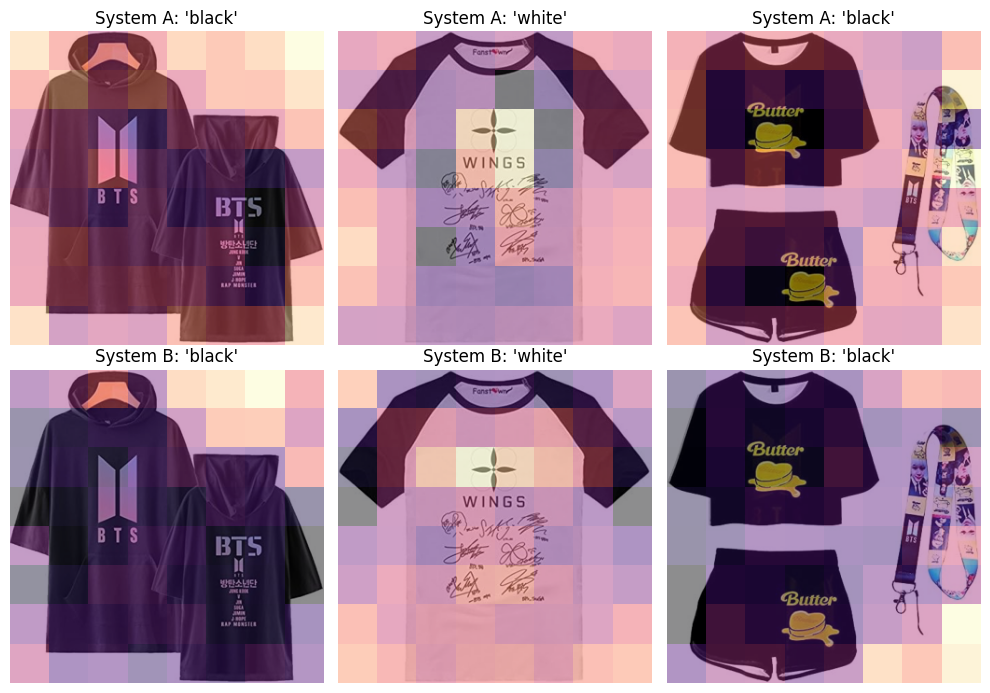

In [26]:
import matplotlib.pyplot as plt

# Select three products that have a reference colour label
examples = Kpop_items.dropna(subset=["ref_colour"]).sample(
    3,
    random_state=1
)

# Create a grid of plots -> represents a system, and each column represents an image
fig, axes = plt.subplots(
    len(RUN_SYSTEMS),
    3,
    figsize=(10, 3.5 * len(RUN_SYSTEMS)),
    squeeze=False
)

# Generate occlusion maps for each system
for row, system in enumerate(RUN_SYSTEMS):

    # Load the model for the current system
    tagger = ZeroShottag(
        MODELS[system]["id"],
        MODELS[system]["kind"]
    )

    # Process each selected product image
    for col, (_, r) in enumerate(examples.iterrows()):

        # Generate the original image and its occlusion map -> uding ref color and first propmt
        img, heat = tagger.Compare_map(   
            r["image_path"],
            r["ref_colour"],
            PROMPT_TEMPLATES[0]
        )

        # Select the subplot for the current image and system
        ax = axes[row, col]

        # Display orignial products
        ax.imshow(img)

        # Overlay the occlusion heatmap on the image -> alpha controls transparency, while magma sets the colour scheme
        ax.imshow(
            heat,
            alpha=0.45,
            cmap="magma",
            extent=(0, img.shape[1], img.shape[0], 0)
        )

        # Add a title showing the system and reference colour
        ax.set_title(f"System {system}: '{r['ref_colour']}'")

        # Hide axis labels and borders for a cleaner visualisation
        ax.axis("off")

    # Remove the model from memory after processing the current system
    del tagger
    free_gpu()

fig.tight_layout()
fig.savefig(FIGURES / f"{TASK}_saliency.png", dpi=200)
plt.show()


# 9. Trend Output

* I will use it to identify **Arttribute** of interesting trend in products , which consider from last **growth records**

> **Logicd:** it will choose model that have highest value of **Tagging Marcro F1** then bring model prediction' label to combine with reviewing data, resulting in ranking attribute follow growth. Then it will shown **Attribute** by rabking 5 first growth and record in csv for using in Notebook Section 2 - Additional Trend Analysis

In [27]:
# Select the system with the highest tagging Macro-F1 score
best = max(
    summary,
    key=lambda s: summary[s]["tag_macro_f1"]
)

# Load the saved predictions from the selected system
tags = pd.read_csv(TABLES / f"{TASK}__{best}_tags.csv")

# Find the latest month available in the review dataset
latest = reviews["month"].max()

# Rank attributes according to their recent review growth -> top 5
trend_table = pd.DataFrame({
    a: rank_growth(
        monthly_counts(
            reviews,
            tags.rename(columns={f"pred_{a}": a}),
            a
        ),
        latest
    )[:5]
    for a in ATTRIBUTES
})

# Replace the row index with ranking numbers
trend_table.index = [
    f"#{i + 1}" for i in range(len(trend_table))
]

# Save the rising attributes to CSV 
trend_table.to_csv(
    TABLES / f"{TASK}__rising_attributes.csv"
)

print(
    f"Rising attributes up to {latest} "
    f"(System {best} tags):"
)

trend_table

Rising attributes up to 2023-08 (System B tags):


,colour,product
#1,white,bag
#2,green,card
#3,yellow,photocard holder
#4,pink,hoodie
#5,purple,keyring


# 10. Conclusion

System A (clip-vit-large-patch14)  \
Technical  Tag macro-F1 (higher = better)                                     0.376   
           Colour F1                                                          0.439   
           Product F1                                                         0.312   
           Trend precision@3                                                  0.250   
           Naive baseline precision@3                                         0.333   
Business   Latency per image (s, lower = better)                              0.015   
           Cost per 1,000 images (USD)                                        0.000   
           Peak GPU memory (GB)                                               1.070   
Governance Multilingual gap (lower = fairer)                                  0.415   
           Colour F1 - English                                                0.439   
           Colour F1 - Korean                                                 0.024   
           Colour F1 - Thai                                                   0.028   

                                                  System B (siglip2-so400m-patch14-384)  
Technical  Tag macro-F1 (higher = better)                                         0.477  
           Colour F1                                                              0.550  
           Product F1                                                             0.404  
           Trend precision@3                                                      0.333  
           Naive baseline precision@3                                             0.333  
Business   Latency per image (s, lower = better)                                  0.063  
           Cost per 1,000 images (USD)                                            0.002  
           Peak GPU memory (GB)                                                   2.750  
Governance Multilingual gap (lower = fairer)                                      0.171  
           Colour F1 - English                                                    0.550  
           Colour F1 - Korean                                                     0.578  
           Colour F1 - Thai                                                       0.407


Does the model beat the naive forecast?
  System A: 0.250 vs naive 0.333 -> NO
  System B: 0.333 vs naive 0.333 -> NO

Better system per dimension:
  Tagging accuracy (macro-F1): System B
  Trend detection (precision@3): System B
  Speed / cost: System A
  Multilingual fairness (gap): System B


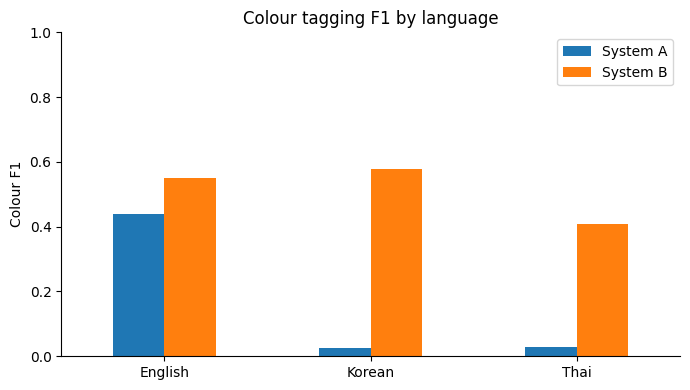


Rising attributes up to 2023-08, System A vs System B:


,colour,product,colour,product
,System A,System A,System B,System B
#1,yellow,bag,white,bag
#2,red,card,green,card
#3,purple,hoodie,yellow,photocard holder
#4,blue,phone case,pink,hoodie
#5,pastel,tea cup,purple,keyring


  colour: 2/5 shared -> ['purple', 'yellow']
  product: 3/5 shared -> ['bag', 'card', 'hoodie']

 Suggestion: Notebook 2 uses System B (highest tagging macro-F1) -> input for Notebook 2


In [28]:
import matplotlib.pyplot as plt

records = {s: json.loads((METRICS / f"{TASK}__{s}.json").read_text(encoding="utf-8")) for s in RUN_SYSTEMS}

rows = {
    ("Technical", "Tag macro-F1 (higher = better)"):         {s: r["technical"]["tag_macro_f1"] for s, r in records.items()},
    ("Technical", "Colour F1"):                               {s: r["technical"]["tag_f1_colour"] for s, r in records.items()},
    ("Technical", "Product F1"):                              {s: r["technical"]["tag_f1_product"] for s, r in records.items()},
    ("Technical", "Trend precision@3"):                       {s: r["technical"]["trend_precision_at_k"] for s, r in records.items()},
    ("Technical", "Naive baseline precision@3"):              {s: r["technical"]["naive_precision_at_k"] for s, r in records.items()},
    ("Business", "Latency per image (s, lower = better)"):    {s: r["business"]["mean_latency_s"] for s, r in records.items()},
    ("Business", "Cost per 1,000 images (USD)"):              {s: r["business"]["cost_per_1000_usd"] for s, r in records.items()},
    ("Business", "Peak GPU memory (GB)"):                     {s: r["business"]["peak_vram_gb"] for s, r in records.items()},
    ("Governance", "Multilingual gap (lower = fairer)"):      {s: r["governance"]["multilingual_gap"] for s, r in records.items()},
}
for lang in records[RUN_SYSTEMS[0]]["governance"]["colour_f1_by_language"]:
    rows[("Governance", f"Colour F1 - {lang}")] = {s: r["governance"]["colour_f1_by_language"][lang] for s, r in records.items()}

summary_table = pd.DataFrame(rows).T
summary_table.columns = [f"System {s} ({MODELS[s]['id'].split('/')[-1]})" for s in RUN_SYSTEMS]
display(summary_table.round(3))
summary_table.to_csv(TABLES / f"{TASK}__summary.csv")

# BASELINE CHECK 
print("\nDoes the model beat the naive forecast?")
for s, r in records.items():
    t, n = r["technical"]["trend_precision_at_k"], r["technical"]["naive_precision_at_k"]
    verdict = "YES" if t > n else ("TIE" if t == n else "NO")
    print(f"  System {s}: {t:.3f} vs naive {n:.3f} -> {verdict}")

# WINNER PER DIMENSION
better = {
    "Tagging accuracy (macro-F1)": max(RUN_SYSTEMS, key=lambda s: records[s]["technical"]["tag_macro_f1"]),
    "Trend detection (precision@3)": max(RUN_SYSTEMS, key=lambda s: records[s]["technical"]["trend_precision_at_k"]),
    "Speed / cost": min(RUN_SYSTEMS, key=lambda s: records[s]["business"]["cost_per_1000_usd"]),
    "Multilingual fairness (gap)": min(RUN_SYSTEMS, key=lambda s: records[s]["governance"]["multilingual_gap"]),
}
print("\nBetter system per dimension:")
for k, s in better.items():
    print(f"  {k}: System {s}")

# CHART 
lang_f1 = pd.DataFrame({f"System {s}": r["governance"]["colour_f1_by_language"] for s, r in records.items()})
ax = lang_f1.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_ylabel("Colour F1"); ax.set_ylim(0, 1); ax.set_title("Colour tagging F1 by language")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIGURES / f"{TASK}_f1_by_language.png", dpi=200); plt.show()

# RISING ATTRIBUTES 
rising = {}
for s in RUN_SYSTEMS:
    sys_tags = pd.read_csv(TABLES / f"{TASK}__{s}_tags.csv")
    for a in ATTRIBUTES:
        ranked = rank_growth(monthly_counts(reviews, sys_tags.rename(columns={f"pred_{a}": a}), a), latest)
        rising[(a, f"System {s}")] = pd.Series(ranked[:5])

rising_table = pd.DataFrame(rising)
rising_table.index = [f"#{i + 1}" for i in range(len(rising_table))]
rising_table.to_csv(TABLES / f"{TASK}__rising_attributes_A_vs_B.csv")

print(f"\nRising attributes up to {latest}, System A vs System B:")
display(rising_table)

# AGREEMENT -
for a in ATTRIBUTES:
    shared = set(rising_table[(a, "System A")].dropna()) & set(rising_table[(a, "System B")].dropna())
    print(f"  {a}: {len(shared)}/5 shared -> {sorted(shared)}")

print(f"\n Suggestion: Notebook 2 uses System {best} (highest tagging macro-F1) -> input for Notebook 2")

# 11. Import all result from Google Drive

Due to I used Google Colab Extention to do a Computer unit so all result will collect in google drive.
Then I do need to do this part for download all result in zip file and manually paste in result file

In [29]:
from pathlib import Path

print("Working directory:", Path.cwd())
print("Results path:", RESULTS.resolve())
print("Results exists:", RESULTS.exists())

print("\nCSV files found:")
csv_files = list(RESULTS.rglob("*.csv"))

for f in csv_files:
    print(f.resolve())

print(f"\nTotal CSV files: {len(csv_files)}")

Working directory: /content
Results path: /content/Results
Results exists: True

CSV files found:
/content/Results/tables/1_Trend_Analysis__rising_attributes_A_vs_B.csv
/content/Results/tables/1_Trend_Analysis__rising_attributes.csv
/content/Results/tables/1_Trend_Analysis__A_tags.csv
/content/Results/tables/1_Trend_Analysis__B_tags.csv
/content/Results/tables/1_Trend_Analysis__summary.csv

Total CSV files: 5


In [30]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [32]:

import shutil
from pathlib import Path

source_folder = Path("/content/Results")
source = Path("/content/Results.zip")
destination = Path("/content/drive/MyDrive/Results.zip")

# create zip first
assert source_folder.exists(), "Results folder not found"
shutil.make_archive(str(source.with_suffix("")), "zip", source_folder)

# copy to drive
assert destination.parent.exists(), "Google Drive not mounted"
shutil.copy2(source, destination)

print("Copy successful:", destination.exists())
print("Saved to:", destination)
print("Size (MB):", round(destination.stat().st_size / 1024**2, 2))


Copy successful: True
Saved to: /content/drive/MyDrive/Results.zip
Size (MB): 1.18


# Live DEMO Section

To avoid over time execution , so I will state this section to mainly shown execution video while introduce all the part of code too.

LIVE DEMO - Notebook 1: Trend Analysis


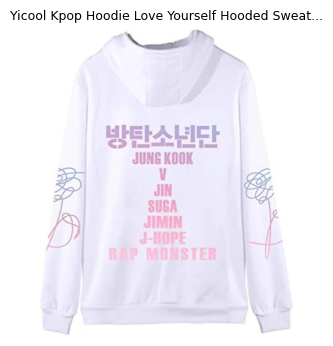

INPUT title: Yicool Kpop Hoodie Love Yourself Hooded Sweatshirts Jimin Suga Jung Kook V Black Hoodie Fans Merchandise
Reference from title -> colour: black | product: hoodie


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]


--- System A: openai/clip-vit-large-patch14 ---
  colour  : white              (63.9%) ❌
  product : hoodie             (92.8%) ✅
  colour in Korean : 노란색 = yellow (21.7%)
  colour in Thai   : สีม่วง = purple (29.9%)


Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]


--- System B: google/siglip2-so400m-patch14-384 ---
  colour  : white              (80.7%) ❌
  product : hoodie             (83.0%) ✅
  colour in Korean : 흰색 = white (59.5%)
  colour in Thai   : สีขาว = white (44.3%)

OUTPUT: rising attributes (input for Notebook 2)


,colour,product,colour,product
,System A,System A,System B,System B
#1,yellow,bag,white,bag
#2,red,card,green,card
#3,purple,hoodie,yellow,photocard holder
#4,blue,phone case,pink,hoodie
#5,pastel,tea cup,purple,keyring


In [34]:
import random
import matplotlib.pyplot as plt
from PIL import Image

print("LIVE DEMO - Notebook 1: Trend Analysis")

# INPUT -> pick one random product that has reference labels from its title
demo = Kpop_items.dropna(subset=["ref_colour", "ref_product"])
demo = demo if len(demo) else Kpop_items.dropna(subset=["ref_product"])
r = demo.sample(1, random_state=random.randint(0, 10_000)).iloc[0]
img = Image.open(r["image_path"]).convert("RGB")

plt.figure(figsize=(4, 4)); plt.imshow(img); plt.axis("off")
plt.title(str(r["title"])[:45] + "...", fontsize=9); plt.show()
print("INPUT title:", r["title"])
print(f"Reference from title -> colour: {r['ref_colour']} | product: {r['ref_product']}")

# MODELS -> each system tags the same image 
for system in RUN_SYSTEMS:
    spec = MODELS[system]
    tagger = ZeroShottag(spec["id"], spec["kind"])
    emb = tagger.encode_images([img])
    print(f"\n--- System {system}: {spec['id']} ---")

    for a, vocab in ATTRIBUTES.items():
        probs = (100 * emb @ tagger.encode_text(vocab, PROMPT_TEMPLATES).T).softmax(-1)[0]
        pred, ref = vocab[int(probs.argmax())], r[f"ref_{a}"]
        mark = "" if pd.isna(ref) else ("✅" if pred == ref else "❌")
        print(f"  {a:8s}: {pred:18s} ({probs.max().item() * 100:.1f}%) {mark}")

    # Same colour question in multilanguages (multilingual fairness)
    for lang, words in COLOUR_LABELS.items():
        probs = (100 * emb @ tagger.encode_text(words, ["{}"]).T).softmax(-1)[0]
        i = int(probs.argmax())
        print(f"  colour in {lang:7s}: {words[i]} = {ATTRIBUTES['colour'][i]} ({probs.max().item() * 100:.1f}%)")

    del tagger; free_gpu()

# OUTPUT for using in notebook 2
if "rising_table" in globals():
    print("\nOUTPUT: rising attributes (input for Notebook 2)")
    display(rising_table)
elif "trend_table" in globals():
    print("\nOUTPUT: rising attributes (input for Notebook 2)")
    display(trend_table)